# 13. 강판 결함 — TabPFN 설정 확장과 OOF 결합

TabPFN 9개 설정·난수별 확률 평균 3개와 HGB·TabICL·XGBoost 확률 결합·스태킹을 실제 실행한 결과입니다. **설정 선택은 Train 내부에서 수행하고, 외부 Fold로 전체 선택 절차를 평가했습니다.**

이 노트북은 실제 결과 검증과 저장 모델의 원본 27열 예측을 실행합니다. 전체 학습은 `run_pfn_expansion.py`에서 수행했습니다. 기본 실행으로 전체 탐색을 다시 학습하지 않습니다.

압축을 풀고 `steel_fault_pfn_expansion` 폴더를 VS Code에서 여세요. README의 설치 명령을 실행한 Python 3.12 커널을 선택하세요.

In [1]:
from pathlib import Path
import os,sys,importlib.metadata as im
ROOT=Path.cwd()
if not (ROOT/"pfn_common.py").exists() and (ROOT/"steel_fault_pfn_expansion/pfn_common.py").exists():
    ROOT=ROOT/"steel_fault_pfn_expansion"
    os.chdir(ROOT)
if not (ROOT/"pfn_common.py").exists():
    raise FileNotFoundError("압축을 해제한 steel_fault_pfn_expansion 폴더를 VS Code에서 여세요.")
sys.path.insert(0,str(ROOT))
import pfn_common as e
import numpy as np
import pandas as pd
import torch
from IPython.display import display,Image
torch.set_num_threads(2)
OUT=e.OUT
print("Python",sys.version.split()[0],"GPU",torch.cuda.is_available())
for name in ["torch","tabpfn","tabicl","scikit-learn","xgboost"]:print(name,im.version(name))

Python 3.12.14 GPU False
torch 2.14.1+cpu
tabpfn 9.2.0
tabicl 2.2.0
scikit-learn 1.8.0
xgboost 3.4.1


## 1. 고정 데이터와 평가 범위

기존 Train 1,358·Validation 291·Test 292를 유지합니다. 입력은 원본 27개 측정값입니다. 그룹은 실제 코일 ID가 아닌 유사 후보 연결성분입니다.

In [2]:
X,y,groups,folds,split=e.data()
display(pd.DataFrame({"구분":["Train","Validation","기존 Test"],"행 수":[len(X),len(split["valid"]),len(split["sealed_test_indices"])]}))
display(y.value_counts().rename("Train 행 수").to_frame())
print("원본 입력 특성:",X.shape[1],"/ Test 예측: 0 / 라벨 변경: 0 / 데이터 병합: 0")

원본 입력 특성: 27 / Test 예측: 0 / 라벨 변경: 0 / 데이터 병합: 0


,구분,행 수
0,Train,1358
1,Validation,291
2,기존 Test,292


,Train 행 수
Other_Faults,471
Bumps,282
K_Scatch,273
Z_Scratch,133
Pastry,110
Stains,50
Dirtiness,39


## 2. TabPFN 9개 설정과 평균 3개

평균은 정확도의 평균이 아니라 각 모델이 낸 예측 확률의 평균입니다. 사전학습 가중치를 미세조정한 실험은 아닙니다.

In [3]:
display(pd.DataFrame([{"candidate":name,**s} for name,s in e.specs().items()]))
display(pd.DataFrame([{"candidate":name,"members":members,
                       "total_forward_members":sum(e.specs()[m]["n_estimators"] for m in members)}
                      for name,members in e.recipes().items()]))
protocol=e.read(OUT/"00_protocol.json")
print("내부 OOF:",protocol["inner_oof"])
print("확률 결합 가중치:",protocol["blend_PFN_weights"])
print("스태킹 C:",protocol["stack_C"],"/ 입력:",protocol["stack_inputs"])

내부 OOF: group3 seed42; selected PFN recipe; HGB/TabICL/XGB caches with identical splits
확률 결합 가중치: [1.0, 0.95, 0.9, 0.8, 0.7, 0.6, 0.5, 0.25, 0.0]
스태킹 C: [0.01, 0.1, 1.0, 10.0] / 입력: ['prob', 'logp']


,candidate,n_estimators,random_state,version
0,PFN4_s42,4,42,v2
1,PFN4_s2026,4,2026,v2
2,PFN4_s20261016,4,20261016,v2
3,PFN8_s42,8,42,v2
4,PFN8_s2026,8,2026,v2
5,PFN8_s20261016,8,20261016,v2
6,PFN16_s42,16,42,v2
7,PFN16_s2026,16,2026,v2
8,PFN16_s20261016,16,20261016,v2


,candidate,members,total_forward_members
0,PFN4_s42,[PFN4_s42],4
1,PFN4_s2026,[PFN4_s2026],4
2,PFN4_s20261016,[PFN4_s20261016],4
3,PFN8_s42,[PFN8_s42],8
4,PFN8_s2026,[PFN8_s2026],8
5,PFN8_s20261016,[PFN8_s20261016],8
6,PFN16_s42,[PFN16_s42],16
7,PFN16_s2026,[PFN16_s2026],16
8,PFN16_s20261016,[PFN16_s20261016],16
9,PFN4_mean3,"[PFN4_s42, PFN4_s2026, PFN4_s20261016]",12


## 3. Train 내부에서 설정 선택

각 외부 Train 안의 보류 분할에서 설정을 고르고, 선택된 설정으로 그 Train의 3-Fold OOF를 만듭니다. OOF의 각 행은 해당 모델의 fit·문맥에서 제외됩니다. 설정 선택에는 부모 Train의 정답을 사용하므로 내부 점수는 독립 일반화 성능이 아닙니다.

context,full_train,outer1,outer2,outer3,outer4,outer5
candidate,,,,,,
PFN16_mean3,0.816176,0.834862,0.839450,0.834101,0.838710,0.807339
PFN16_s2026,0.819853,0.830275,0.821101,0.838710,0.834101,0.821101
PFN16_s20261016,0.819853,0.830275,0.839450,0.852535,0.838710,0.811927
PFN16_s42,0.816176,0.830275,0.834862,0.838710,0.815668,0.802752
PFN4_mean3,0.823529,0.834862,0.844037,0.834101,0.843318,0.798165
PFN4_s2026,0.812500,0.839450,0.848624,0.838710,0.843318,0.798165
PFN4_s20261016,0.812500,0.816514,0.834862,0.834101,0.820276,0.807339
PFN4_s42,0.819853,0.834862,0.839450,0.834101,0.824885,0.816514
PFN8_mean3,0.819853,0.821101,0.834862,0.838710,0.834101,0.811927


,context,selected_PFN
0,outer1,PFN4_s2026
1,outer2,PFN4_s2026
2,outer3,PFN16_s20261016
3,outer4,PFN4_mean3
4,outer5,PFN16_s2026
5,full_train,PFN4_mean3


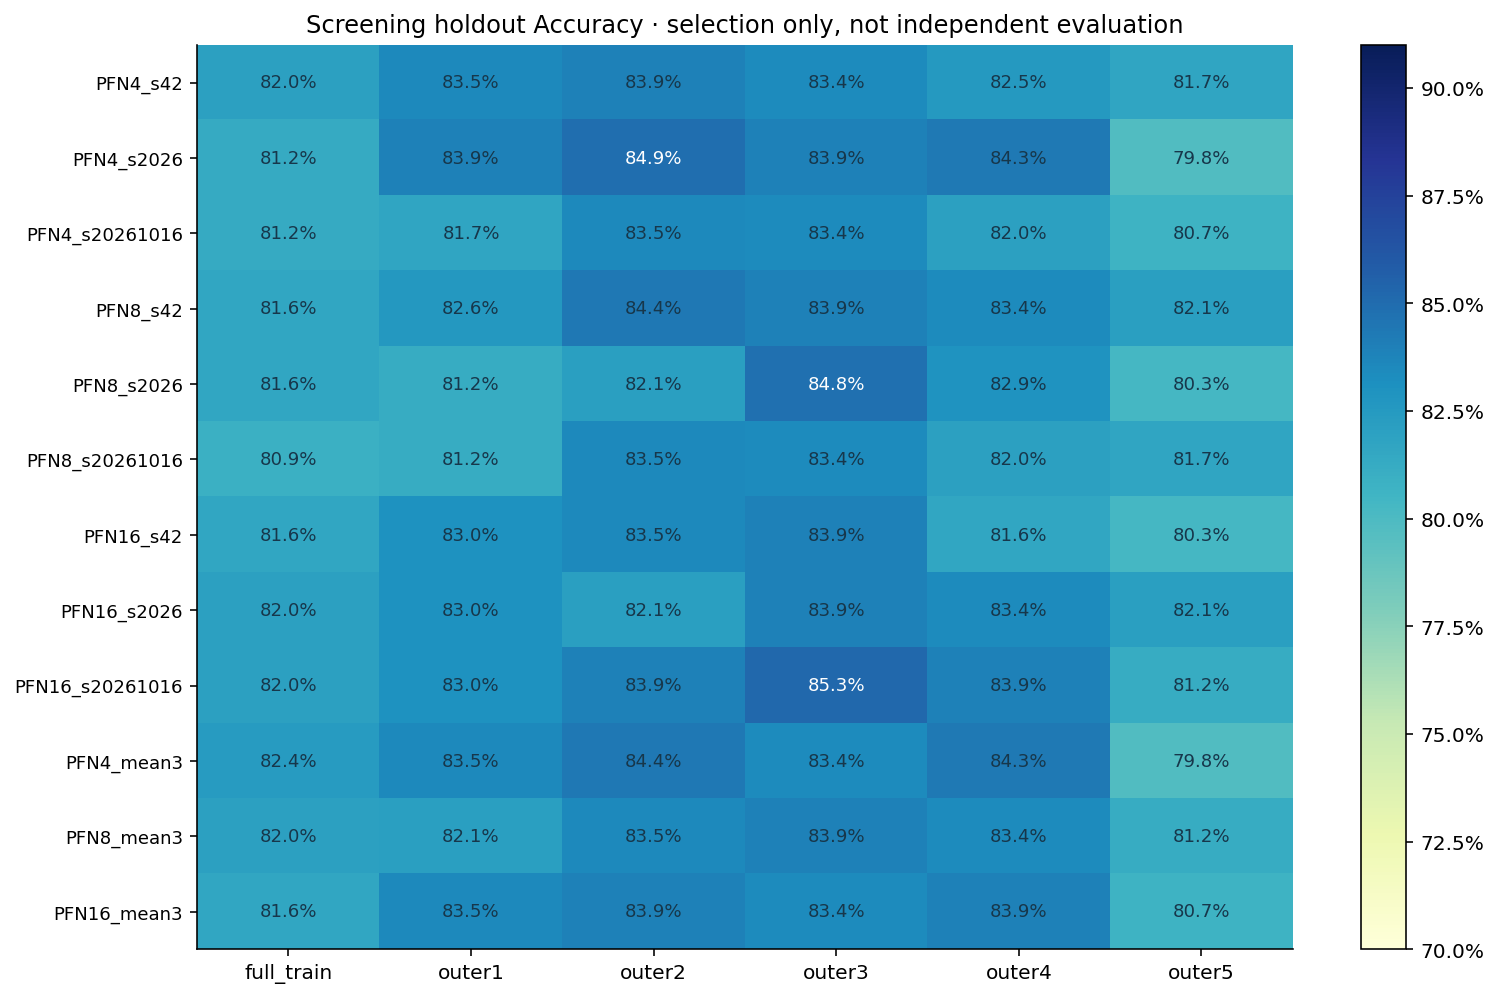

In [4]:
screen=pd.read_csv(OUT/"01_screen_comparison.csv",encoding="utf-8-sig")
display(screen.pivot(index="candidate",columns="context",values="accuracy"))
display(pd.DataFrame([{"context":name,"selected_PFN":s["selected_recipe"]}
                      for name,s in e.read(OUT/"01_screen_selections.json").items()]))
display(Image(filename=str(OUT/"figures/01_screening.png")))

## 4. 외부 5-Fold 평가

SelectedPFN과 각 결합 가족은 Fold마다 내부에서 설정을 선택하는 절차입니다. 특정 고정 PFN 설정 하나의 CV로 읽지 마세요. Nested_selector는 7개 가족 중 하나를 선택하는 전체 절차입니다. SD는 신뢰구간이 아닙니다.

,candidate,correct,rows,accuracy,macro_f1,macro_recall,dirtiness_recall,cv_accuracy_mean,cv_accuracy_std,sd_ddof
8,PFN4_s42_reference,1132,1358,0.833579,0.854967,0.850777,0.871795,0.833582,0.020083,0
2,Stack_PHGB,1131,1358,0.832842,0.857790,0.847879,0.923077,0.832844,0.014623,0
3,Blend_PTabICL,1127,1358,0.829897,0.844901,0.842486,0.846154,0.829897,0.022964,0
0,SelectedPFN,1125,1358,0.828424,0.842726,0.839508,0.846154,0.828430,0.020999,0
7,Nested_selector,1125,1358,0.828424,0.846670,0.839924,0.871795,0.828421,0.023162,0
5,Blend_PXGB,1124,1358,0.827688,0.844847,0.841527,0.871795,0.827686,0.023363,0
4,Stack_PTabICL,1123,1358,0.826951,0.844922,0.834010,0.846154,0.826943,0.011286,0
1,Blend_PHGB,1119,1358,0.824006,0.841800,0.839223,0.871795,0.824015,0.018914,0
6,Stack_PXGB,1117,1358,0.822533,0.845634,0.829522,0.846154,0.822520,0.020862,0


,context,PFN_recipe,family
0,outer1,PFN4_s2026,Stack_PTabICL
1,outer2,PFN4_s2026,Blend_PXGB
2,outer3,PFN16_s20261016,Blend_PXGB
3,outer4,PFN4_mean3,Stack_PHGB
4,outer5,PFN16_s2026,SelectedPFN


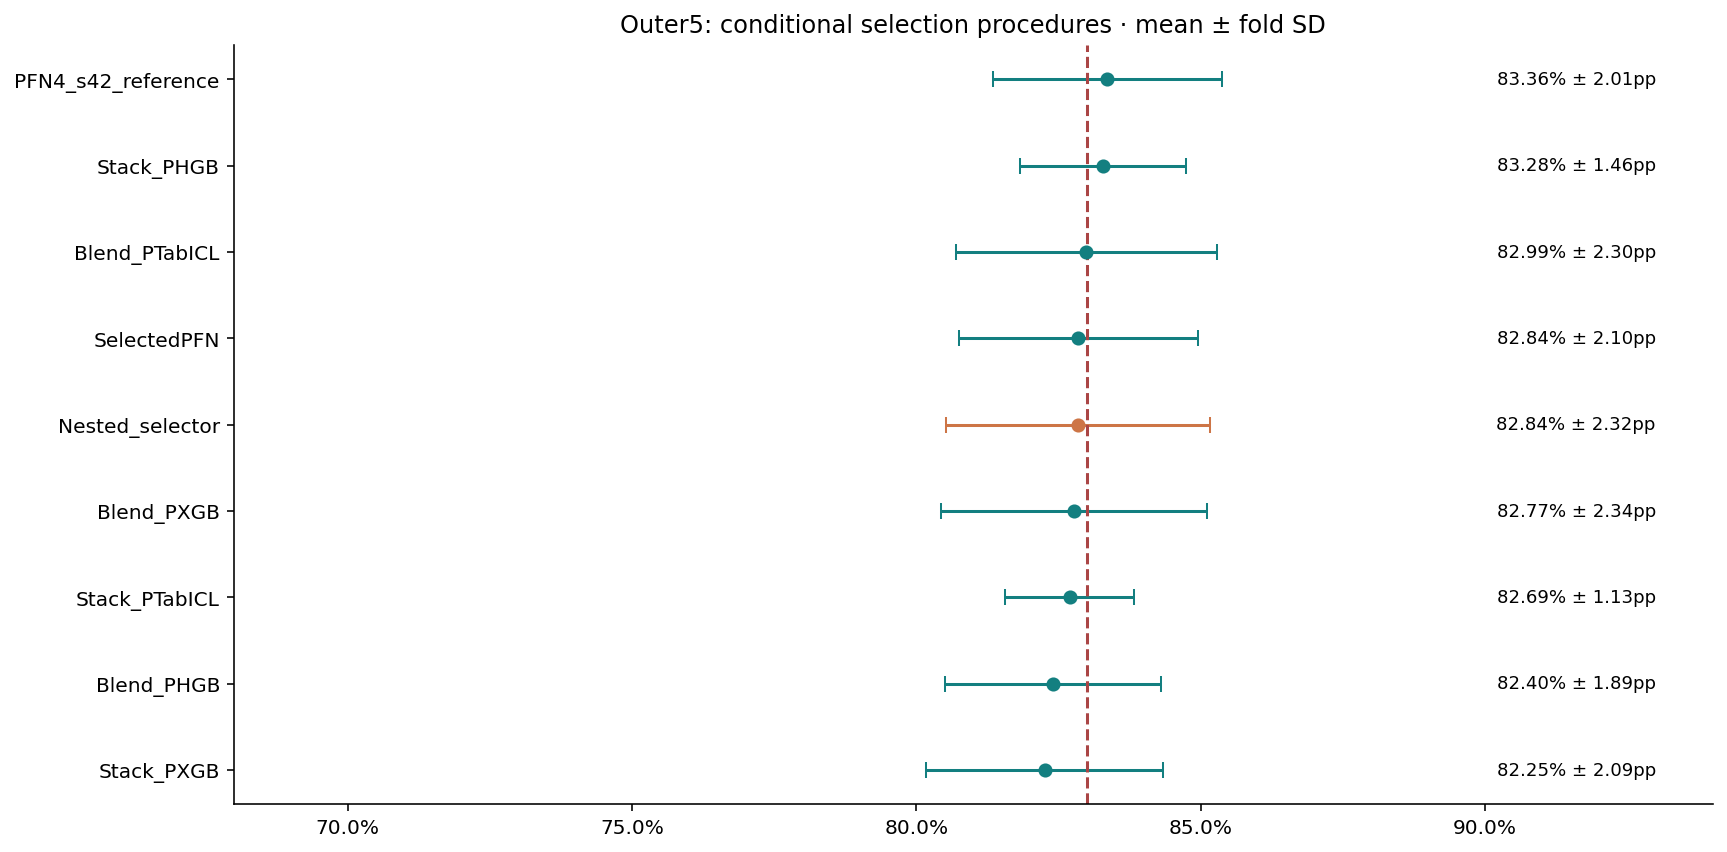

In [5]:
cv=pd.read_csv(OUT/"03_outer_cv_summary.csv",encoding="utf-8-sig")
display(cv.sort_values("cv_accuracy_mean",ascending=False))
display(pd.DataFrame(e.read(OUT/"03_outer_selections.json")))
display(Image(filename=str(OUT/"figures/02_outer_cv.png")))

## 5. 외부 평가의 오류 교환

이전 PFN4·seed42가 틀렸던 것을 고친 건수와 기존 정답을 잃은 건수를 함께 확인합니다. 과거 탐색 이력이 있는 같은 자료의 기술적 비교입니다.

In [6]:
display(pd.read_csv(OUT/"08_outer_paired_changes.csv",encoding="utf-8-sig"))
display(pd.read_csv(OUT/"08_outer_fold_differences.csv",encoding="utf-8-sig"))

,candidate,reference,rows,rescued,lost_correct,net_correct
0,SelectedPFN,PFN4_s42_reference,1358,26,33,-7
1,Nested_selector,PFN4_s42_reference,1358,27,34,-7


,candidate,fold,accuracy,reference_accuracy,difference_pp
0,SelectedPFN,1,0.845588,0.849265,-0.367647
1,SelectedPFN,2,0.808118,0.808118,0.000000
2,SelectedPFN,3,0.801471,0.819853,-1.838235
3,SelectedPFN,4,0.830882,0.827206,0.367647
4,SelectedPFN,5,0.856089,0.863469,-0.738007
5,Nested_selector,1,0.838235,0.849265,-1.102941
6,Nested_selector,2,0.797048,0.808118,-1.107011
7,Nested_selector,3,0.805147,0.819853,-1.470588
8,Nested_selector,4,0.845588,0.827206,1.838235
9,Nested_selector,5,0.856089,0.863469,-0.738007


## 6. Validation 이전에 고정한 최종 규칙

아래 기본 모델은 Validation 최고값으로 바꾼 모델이 아닙니다.

In [7]:
frozen=e.read(OUT/"04_frozen_before_validation.json")
print("Train 선정 기본 모델:",frozen["primary"])
print("Train 선정 PFN:",frozen["selected_PFN"]["selected_recipe"])
print("Validation 정답 사용:",frozen["validation_labels_used"])
display(pd.DataFrame(frozen["internal_family_scores_not_independent"]))
display(pd.DataFrame([{"candidate":name,**rule} for name,rule in frozen["rules"].items()]))

Train 선정 기본 모델: PFN4_mean3
Train 선정 PFN: PFN4_mean3
Validation 정답 사용: False


,candidate,accuracy,macro_f1,macro_recall,dirtiness_recall
0,SelectedPFN,0.826215,0.850706,0.843462,0.897436
1,Blend_PHGB,0.824006,0.849532,0.842349,0.897436
2,Blend_PTabICL,0.825479,0.847498,0.840612,0.871795
3,Blend_PXGB,0.824742,0.849901,0.842652,0.897436
4,Stack_PHGB,0.814433,0.837381,0.821760,0.871795
5,Stack_PTabICL,0.818851,0.843765,0.828082,0.871795
6,Stack_PXGB,0.816642,0.840771,0.823637,0.871795


,candidate,kind,other,PFN_weight,weight_sum,mode,C,meta_fit_rows,meta_input
0,SelectedPFN,pfn,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Blend_PHGB,blend,HGB,1.00,1.0,NaN,NaN,NaN,NaN
2,Stack_PHGB,stack,HGB,NaN,NaN,prob,10.0,1358.0,selected PFN and base inner OOF only
3,Blend_PTabICL,blend,TabICL,0.95,1.0,NaN,NaN,NaN,NaN
4,Stack_PTabICL,stack,TabICL,NaN,NaN,prob,10.0,1358.0,selected PFN and base inner OOF only
5,Blend_PXGB,blend,XGB,1.00,1.0,NaN,NaN,NaN,NaN
6,Stack_PXGB,stack,XGB,NaN,NaN,prob,10.0,1358.0,selected PFN and base inner OOF only


## 7. Validation 전체 비교

83% 초과에는 242/291 이상이 필요합니다. 기존 최고 239/291=82.13%와 비교합니다. 반복 사용한 Validation이므로 독립 최종 성능으로 주장하지 않습니다.

Train 선정 기본 모델: {'candidate': 'PFN4_mean3', 'primary_selected_by_Train': True, 'screen_selected_PFN': True, 'correct': 240, 'errors': 51, 'rows': 291, 'accuracy': 0.8247422680412371, 'macro_f1': 0.8099680234698884, 'macro_recall': 0.7933431790083194, 'dirtiness_recall': 0.625, 'strictly_above83': False, 'net_more_correct_needed_for83': 2}
전체 관찰 최고(선택 근거 아님): {'candidate': 'Stack_PHGB', 'primary_selected_by_Train': False, 'screen_selected_PFN': False, 'correct': 242, 'errors': 49, 'rows': 291, 'accuracy': 0.8316151202749141, 'macro_f1': 0.8211574539577932, 'macro_recall': 0.7942389828744203, 'dirtiness_recall': 0.625, 'strictly_above83': True, 'net_more_correct_needed_for83': 0}


,candidate,primary_selected_by_Train,screen_selected_PFN,correct,errors,rows,accuracy,macro_f1,macro_recall,dirtiness_recall,strictly_above83,net_more_correct_needed_for83
13,Stack_PHGB,False,False,242,49,291,0.831615,0.821157,0.794239,0.625,True,0
10,PFN8_mean3,False,False,242,49,291,0.831615,0.813043,0.796172,0.625,True,0
6,PFN16_s42,False,False,241,50,291,0.828179,0.812100,0.793791,0.625,False,1
9,PFN4_mean3,True,True,240,51,291,0.824742,0.809968,0.793343,0.625,False,2
12,Blend_PHGB,False,False,240,51,291,0.824742,0.809968,0.793343,0.625,False,2
16,Blend_PXGB,False,False,240,51,291,0.824742,0.809968,0.793343,0.625,False,2
4,PFN8_s2026,False,False,240,51,291,0.824742,0.809673,0.793343,0.625,False,2
3,PFN8_s42,False,False,240,51,291,0.824742,0.807564,0.791410,0.625,False,2
1,PFN4_s2026,False,False,239,52,291,0.821306,0.808508,0.790962,0.625,False,3
14,Blend_PTabICL,False,False,239,52,291,0.821306,0.808279,0.791929,0.625,False,3


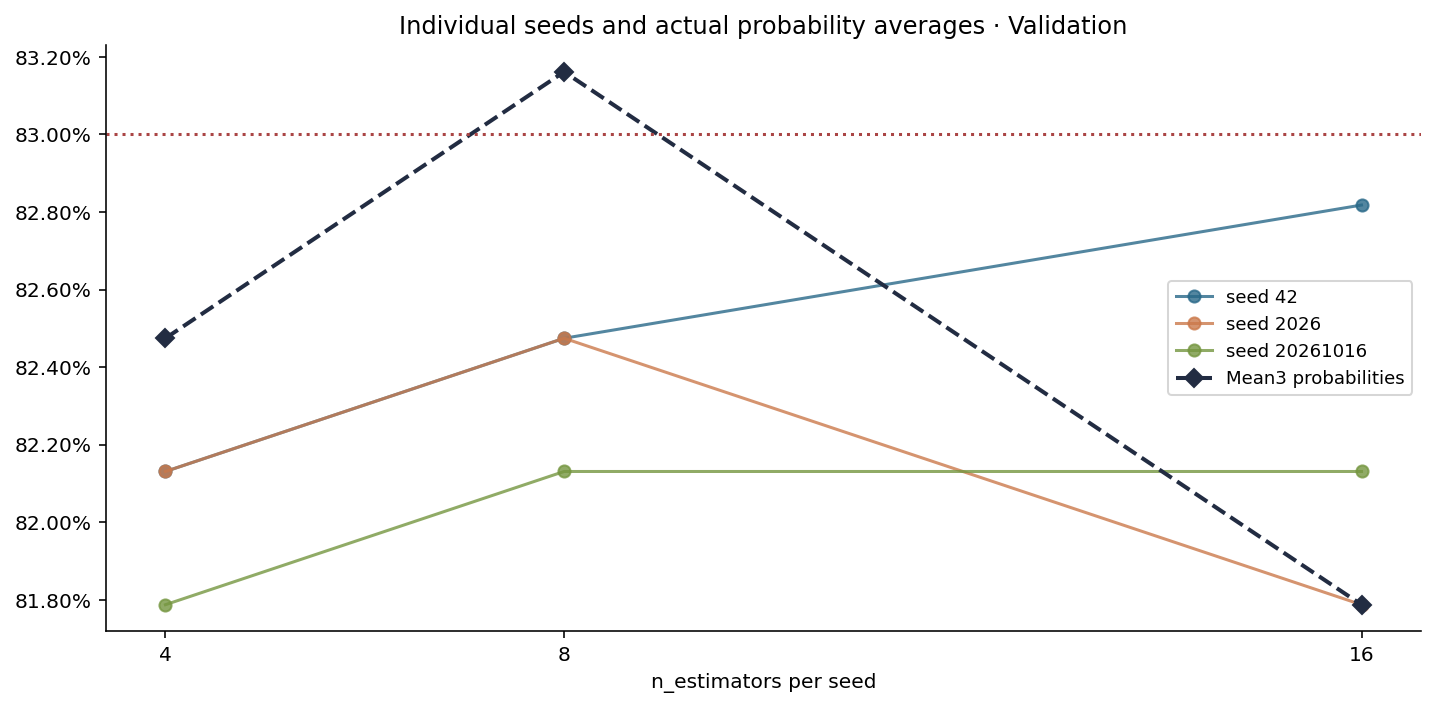

In [8]:
val=pd.read_csv(OUT/"05_validation_comparison.csv",encoding="utf-8-sig")
result=e.read(OUT/"07_result.json")
display(val.sort_values(["accuracy","macro_f1"],ascending=False))
print("Train 선정 기본 모델:",result["primary"])
print("전체 관찰 최고(선택 근거 아님):",result["best_observed_validation_not_selection"])
display(Image(filename=str(OUT/"figures/04_seed_counts.png")))

## 8. 혼동행렬과 클래스별 성능

행은 실제 유형, 열은 예측 유형입니다. Dirtiness는 Validation 8건이므로 한 건이 Recall 12.5%p에 해당합니다.

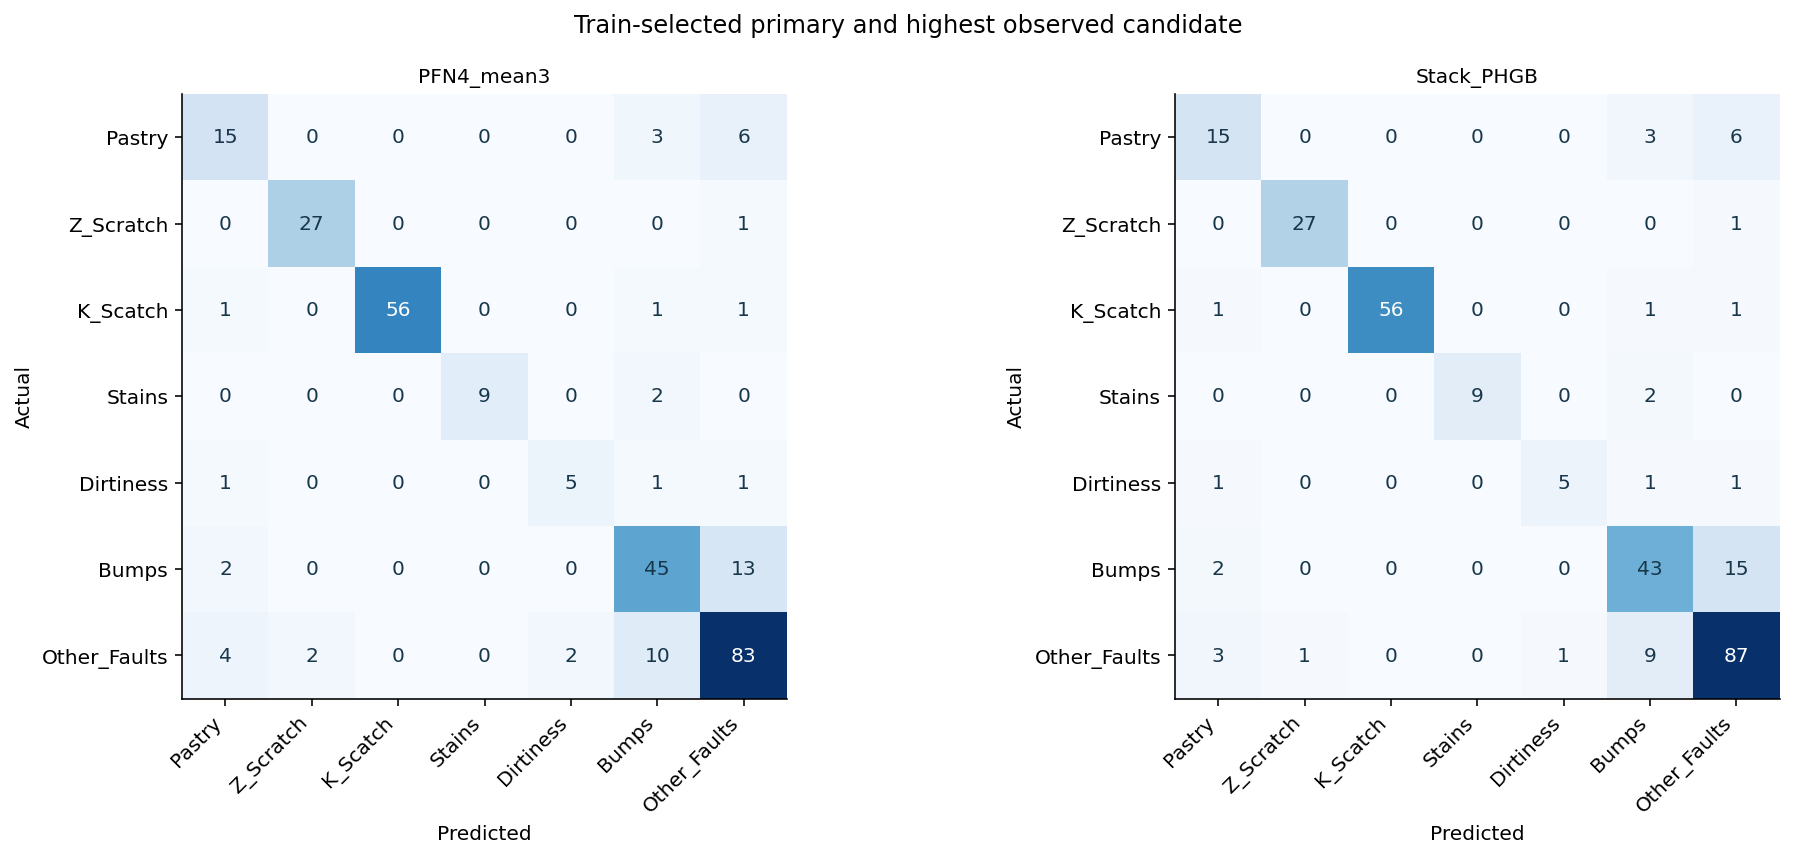

,candidate,class,precision,recall,f1-score,support
0,PFN4_s42,Pastry,0.583333,0.583333,0.583333,24.0
1,PFN4_s42,Z_Scratch,0.962963,0.928571,0.945455,28.0
2,PFN4_s42,K_Scatch,1.000000,0.949153,0.973913,59.0
3,PFN4_s42,Stains,1.000000,0.818182,0.900000,11.0
4,PFN4_s42,Dirtiness,0.714286,0.625000,0.666667,8.0
5,PFN4_s42,Bumps,0.745763,0.733333,0.739496,60.0
6,PFN4_s42,Other_Faults,0.779817,0.841584,0.809524,101.0
63,PFN4_mean3,Pastry,0.652174,0.625000,0.638298,24.0
64,PFN4_mean3,Z_Scratch,0.931034,0.964286,0.947368,28.0
65,PFN4_mean3,K_Scatch,1.000000,0.949153,0.973913,59.0


,candidate,errors,Bumps_Other_bidirectional,Pastry_Other_bidirectional,two_pairs_fraction,Stains_to_Dirtiness,Dirtiness_to_Stains,Other_actual,Other_predicted,Other_TP,Other_FP,Other_FN
0,PFN4_mean3,51,23,10,0.647059,0,0,101,105,83,22,18
1,Stack_PHGB,49,24,9,0.673469,0,0,101,111,87,24,14
2,PFN4_s42,52,22,12,0.653846,0,0,101,109,85,24,16


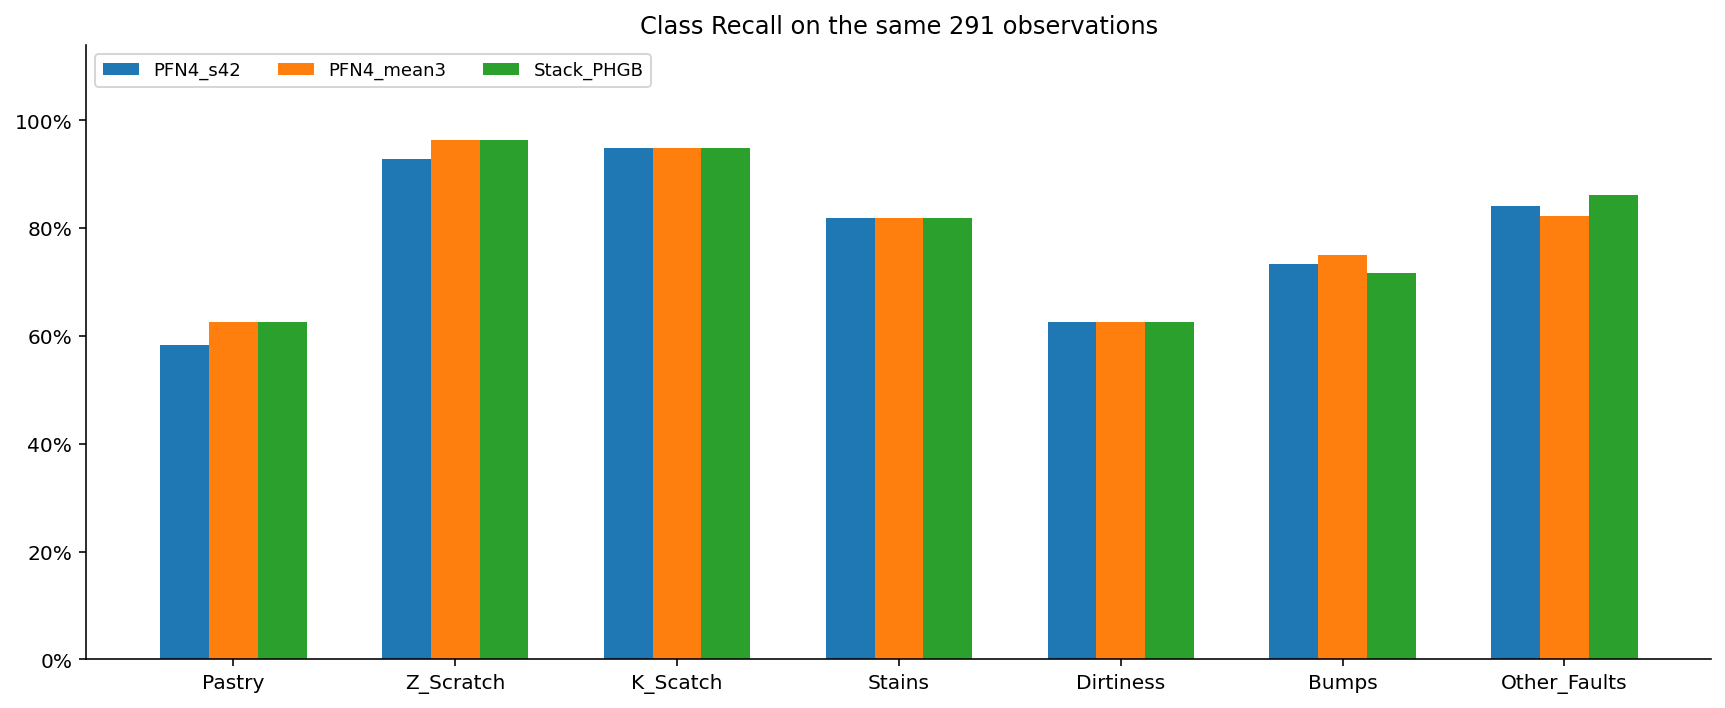

In [9]:
display(Image(filename=str(OUT/"figures/05_confusion.png")))
names=list(dict.fromkeys(["PFN4_s42",frozen["primary"],result["best_observed_validation_not_selection"]["candidate"]]))
classes=pd.read_csv(OUT/"05_class_metrics.csv",encoding="utf-8-sig")
display(classes[classes.candidate.isin(names)])
display(pd.read_csv(OUT/"08_error_focus.csv",encoding="utf-8-sig"))
display(Image(filename=str(OUT/"figures/06_class_recall.png")))

## 9. Validation 오류 교환과 예측 비용

기반 모델의 예측 시간과 완성된 결합 모델의 전체 지연시간을 구분합니다. 공통 PFN 가중치는 모델 크기에 한 번만 셉니다.

In [10]:
changes=pd.read_csv(OUT/"05_error_changes.csv",encoding="utf-8-sig")
display(changes[changes.candidate.isin(names)])
display(pd.read_csv(OUT/"05_predict_times.csv",encoding="utf-8-sig"))
sizes=pd.read_csv(OUT/"08_model_sizes.csv",encoding="utf-8-sig")
display(sizes[sizes.candidate.isin(names)])

,candidate,reference,rescued,lost_correct,net_correct
0,PFN4_s42,PFN4_s42,0,0,0
1,PFN4_s42,Previous_stack81_10,12,9,3
18,PFN4_mean3,PFN4_s42,5,4,1
19,PFN4_mean3,Previous_stack81_10,10,6,4
26,Stack_PHGB,PFN4_s42,7,4,3
27,Stack_PHGB,Previous_stack81_10,12,6,6


,candidate,rows,load_seconds,predict_seconds,reused_probability,workers_in_phase
0,PFN4_s42,291,0.082574,63.424939,False,3
1,PFN4_s2026,291,0.082867,78.261275,False,3
2,PFN4_s20261016,291,0.079635,64.697151,False,3
3,PFN8_s42,291,0.116978,150.568521,False,3
4,PFN8_s2026,291,0.137155,148.511066,False,3
5,PFN8_s20261016,291,0.160320,164.043161,False,3
6,PFN16_s42,291,0.222904,311.616191,False,3
7,PFN16_s2026,291,0.158574,316.702069,False,3
8,PFN16_s20261016,291,0.242919,321.298226,False,3
9,HGB,291,0.118054,0.022553,False,3


,candidate,PFN_forward_members,model_and_required_weights_MiB,shared_PFN_checkpoint_counted_once,size_excludes_small_shared_recipe_bundle
0,PFN4_s42,4,28.948205,True,True
9,PFN4_mean3,12,31.513471,True,True
13,Stack_PHGB,12,32.453164,True,True


## 10. 저장된 기본 모델의 원본 입력 예측을 실제 실행

기존 Validation 첫 3건으로 저장 모델 재호출을 검증합니다. 학습·튜닝을 새로 하지 않습니다.

In [11]:
from predict_pfn import predict_frame
columns=[s.strip() for s in (ROOT/"reference/Faults27x7_var").read_text(encoding="utf-8-sig").splitlines() if s.strip()]
raw=pd.read_csv(ROOT/"reference/Faults.NNA",sep=r"\s+",header=None,names=columns)
sample=raw.loc[split["valid"][:3],columns[:27]]
actual_prediction=predict_frame(sample)
measured=np.load(OUT/"05_validation_probabilities.npz")
q=actual_prediction[["p_"+c for c in e.LABELS]].to_numpy()
np.testing.assert_allclose(q,measured[frozen["primary"]][:3],atol=1e-4)
display(actual_prediction)
print("PASS: 저장 모델 원본 27열 예측이 실제 결과와 일치합니다.")

PASS: 저장 모델 원본 27열 예측이 실제 결과와 일치합니다.


,predicted_fault,max_probability_uncalibrated,p_Pastry,p_Z_Scratch,p_K_Scatch,p_Stains,p_Dirtiness,p_Bumps,p_Other_Faults
1207,Bumps,0.982770,0.000075,0.000027,0.000008,0.000014,0.000013,0.982770,0.017094
1550,Other_Faults,0.898447,0.000712,0.021645,0.056232,0.001194,0.000729,0.021042,0.898447
130,Pastry,0.977530,0.977530,0.000042,0.000030,0.000024,0.000508,0.000664,0.021202


## 11. 학습 범위·선택 절차·점수 독립 대조

원본 행과 그룹 분리, 설정 선택, 실제 예측 확률·혼동행렬, 최종 규칙 해시, 기존 행의 독립 평가 차단을 검사합니다.

In [12]:
from verify_pfn import check
verification=check("validation")
display(pd.Series(verification,name="verification"))

status                                                PASS
phase                                           validation
screen_configuration_contexts                           54
screen_recipes_reconciled                               72
PFN_fit_prediction_records                              91
new_PFN_fit_prediction_records                          84
reused_PFN_prediction_records                            7
original_cache_files_verified                          154
screening_and_probability_class_order_passed          True
validation_fit_rows                                      0
new_Test_predictions                                     0
labels_changed                                           0
rows_deleted                                             0
SMOTE                                                    0
train_valid_merge                                    False
new_defect_images                                    False
independent_evaluation_run                           Fal

## 12. 추가 자료 상태와 재실행

실제 결함 이미지·생산 조건·새 독립 표본이 없어 추가하지 않았습니다. 라벨 변경·Train/Validation 병합·Test 예측도 없습니다.

전체 탐색을 다시 학습하려면 프로젝트 복사본에서 기존 `outputs_pfn`을 보존한 뒤 새 출력 폴더로 다음 명령을 실행하세요.

```bash
python run_pfn_expansion.py --phase screen --workers 3
python verify_pfn.py --phase screen
python run_pfn_expansion.py --phase crossfit --workers 3
python run_pfn_expansion.py --phase finalize_train
python verify_pfn.py --phase train
python run_pfn_expansion.py --phase validation
python verify_pfn.py --phase validation
```

완료된 조건은 재사용합니다. 설정·자료·코드를 바꾼 뒤 이전 캐시와 혼합하지 마세요. 자세한 설치·재현 절차는 README를 참고하세요.

In [13]:
queue=pd.read_csv(ROOT/"previous_oof/03_image_review_queue.csv",encoding="utf-8-sig")
template=pd.read_csv(ROOT/"independent_evaluation_template.csv",encoding="utf-8-sig")
print("Train 이미지·전문가 검토 대기 행:",len(queue))
display(queue.head(3))
print("새 독립 평가 템플릿 행:",len(template))
print("실제 이미지 추가: 0 / 라벨 수정: 0 / Test 예측: 0 / 데이터 병합: 0")

Train 이미지·전문가 검토 대기 행: 863
새 독립 평가 템플릿 행: 0
실제 이미지 추가: 0 / 라벨 수정: 0 / Test 예측: 0 / 데이터 병합: 0


,pair,original_index,row_1based,actual,nearest_other_class_row,nearest_other_class,same_class_distance,other_class_distance,other_to_same_distance_ratio,nearest_non_group_is_other_class,image_reference,original_label,reviewer_label,reviewer,evidence,review_status,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas
0,Bumps / Other_Faults,1816,1817,Other_Faults,1035,Bumps,3.841314,1.346784,0.350605,True,NaN,Other_Faults,NaN,NaN,NaN,unreviewed,57,64,766963,766976,36,9,13,2765,64,93,1694,1,0,211,0.0673,0.6044,0.5385,0.0041,0.7778,1.000,1.0,1.5563,0.8451,1.1139,0.4615,-0.4000,0.1965
1,Bumps / Other_Faults,1034,1035,Bumps,1817,Other_Faults,3.419642,1.346784,0.393838,True,NaN,Bumps,NaN,NaN,NaN,unreviewed,61,67,799291,799301,34,8,10,2588,61,95,1690,1,0,211,0.0722,0.4333,0.6000,0.0036,0.7500,1.000,1.0,1.5315,0.7782,1.0000,0.4000,-0.4053,0.1659
2,Bumps / Other_Faults,1098,1099,Bumps,1391,Other_Faults,6.589396,2.868223,0.435279,True,NaN,Bumps,NaN,NaN,NaN,unreviewed,787,1316,3544454,3544490,8391,609,343,991612,103,140,1364,0,1,40,0.0704,0.5594,0.0680,0.3878,0.8686,0.105,0.0,3.9238,2.7235,1.5563,-0.9319,-0.0768,1.0000
